# Racha ascendente. Comparación de agentes



## 1. Configuración




In [ ]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

CARTAS = (1, 3, 5, 7, 13, "joker", "joker")
INICIO = 49
META = 82
RONDAS = 5
ACCIONES = ("robar", "plantarse")

CONFIGURACIONES = {
    "ε-greedy": ("ε", [0.1, 0.2, 0.4]),
    "UCB": ("c", [0.5, 1.0, 2.0]),
    "H": ("α", [0.05, 0.1, 0.2]),
}
SEMILLAS = [42, 43, 44]
PUNTOS = [0, 10_000, 50_000, 100_000, 200_000]
PARTIDAS_EVALUACION = 20_000
BLOQUE_RECOMPENSAS = 2_000


## 2. Elección de acciones




In [ ]:
def elegir_accion(estado, metodo, parametro, tabla, visitas, azar, entrenando):
    if estado[2] is None:
        return "robar", 1.0

    robar = tabla.get((estado, "robar"), 0.0)
    plantarse = tabla.get((estado, "plantarse"), 0.0)
    prob_robar = None

    if metodo == "H":
        maximo = max(robar, plantarse)
        peso_robar = math.exp(robar - maximo)
        peso_plantarse = math.exp(plantarse - maximo)
        prob_robar = peso_robar / (peso_robar + peso_plantarse)
        if entrenando:
            accion = "robar" if azar.random() < prob_robar else "plantarse"
            return accion, prob_robar

    elif entrenando:
        if metodo == "ε-greedy" and azar.random() < parametro:
            return azar.choice(ACCIONES), None
        if metodo == "UCB":
            pendientes = [a for a in ACCIONES if visitas.get((estado, a), 0) == 0]
            if pendientes:
                return azar.choice(pendientes), None
            total = sum(visitas[(estado, a)] for a in ACCIONES)
            robar += parametro * math.sqrt(math.log(total) / visitas[(estado, "robar")])
            plantarse += parametro * math.sqrt(math.log(total) / visitas[(estado, "plantarse")])

    accion = "plantarse" if plantarse >= robar else "robar"
    return accion, prob_robar


## 3. Juego común




In [ ]:
def jugar(metodo, parametro, tabla, visitas, azar_mazo, azar_politica, entrenando=True):
    puntaje = INICIO
    historial = []

    for ronda in range(1, RONDAS + 1):
        mazo = list(CARTAS)
        azar_mazo.shuffle(mazo)
        mayor = None

        while True:
            estado = (puntaje, RONDAS - ronda + 1, mayor, len(mazo))
            accion, prob_robar = elegir_accion(
                estado, metodo, parametro, tabla, visitas, azar_politica, entrenando
            )
            if entrenando:
                historial.append((estado, accion, prob_robar))
            if accion == "plantarse":
                puntaje += mayor
                break

            carta = mazo.pop()
            if carta == "joker":
                if mayor is not None:
                    puntaje -= 2 * mayor
                break
            if mayor is not None and carta < mayor:
                break
            mayor = carta

        if puntaje >= META or puntaje <= 0:
            break

    recompensa = 1 if puntaje >= META else -1
    return historial, recompensa


## 4. Actualización del aprendizaje




In [ ]:
def actualizar_q(tabla, visitas, historial, recompensa):
    for estado, accion, _ in historial:
        clave = (estado, accion)
        visitas[clave] = visitas.get(clave, 0) + 1
        alpha = 1 / visitas[clave]
        actual = tabla.get(clave, 0.0)
        tabla[clave] = actual + alpha * (recompensa - actual)


def actualizar_h(tabla, visitas, referencias, historial, recompensa, alpha):
    for estado, accion, prob_robar in historial:
        if estado[2] is None:
            continue
        referencia = referencias.get(estado, 0.0)
        indicador_robar = 1.0 if accion == "robar" else 0.0
        cambio = alpha * (recompensa - referencia) * (indicador_robar - prob_robar)
        tabla[(estado, "robar")] = tabla.get((estado, "robar"), 0.0) + cambio
        tabla[(estado, "plantarse")] = tabla.get((estado, "plantarse"), 0.0) - cambio
        clave = (estado, accion)
        visitas[clave] = visitas.get(clave, 0) + 1
        total = sum(visitas.get((estado, a), 0) for a in ACCIONES)
        referencias[estado] = referencia + (recompensa - referencia) / total


## 5. Entrenamiento y evaluación




In [ ]:
def evaluar(metodo, parametro, tabla, visitas, semilla):
    azar = random.Random(semilla)
    victorias = 0
    for _ in range(PARTIDAS_EVALUACION):
        _, recompensa = jugar(metodo, parametro, tabla, visitas, azar, azar, False)
        victorias += int(recompensa == 1)
    return 100 * victorias / PARTIDAS_EVALUACION


def experimentar(metodo, parametro, semilla):
    tabla, visitas, referencias = {}, {}, {}
    azar_mazo = random.Random(semilla)
    azar_politica = random.Random(semilla + 1000)
    curva, curva_recompensas = [], []
    suma_recompensas = 0
    entrenadas = 0

    for objetivo in PUNTOS:
        for partida in range(entrenadas + 1, objetivo + 1):
            historial, recompensa = jugar(
                metodo, parametro, tabla, visitas, azar_mazo, azar_politica
            )
            if metodo == "H":
                actualizar_h(tabla, visitas, referencias, historial, recompensa, parametro)
            else:
                actualizar_q(tabla, visitas, historial, recompensa)
            suma_recompensas += recompensa
            if partida % BLOQUE_RECOMPENSAS == 0:
                curva_recompensas.append(suma_recompensas / BLOQUE_RECOMPENSAS)
                suma_recompensas = 0

        entrenadas = objetivo
        curva.append(evaluar(metodo, parametro, tabla, visitas, semilla + 10000))
    return curva, curva_recompensas


## 6. Ejecutar las comparaciones




In [ ]:
resultados, recompensas = {}, {}

for metodo, (nombre, parametros) in CONFIGURACIONES.items():
    resultados[metodo], recompensas[metodo] = {}, {}
    for parametro in parametros:
        repeticiones, repeticiones_recompensas = [], []
        for semilla in SEMILLAS:
            print(f"{metodo} | {nombre}={parametro} | semilla={semilla}", flush=True)
            curva, curva_recompensas = experimentar(metodo, parametro, semilla)
            repeticiones.append(curva)
            repeticiones_recompensas.append(curva_recompensas)
        resultados[metodo][parametro] = np.array(repeticiones)
        recompensas[metodo][parametro] = np.array(repeticiones_recompensas)


ε-greedy | ε=0.1 | semilla=42
ε-greedy | ε=0.1 | semilla=43
ε-greedy | ε=0.1 | semilla=44
ε-greedy | ε=0.2 | semilla=42
ε-greedy | ε=0.2 | semilla=43
ε-greedy | ε=0.2 | semilla=44
ε-greedy | ε=0.4 | semilla=42
ε-greedy | ε=0.4 | semilla=43
ε-greedy | ε=0.4 | semilla=44
UCB | c=0.5 | semilla=42
UCB | c=0.5 | semilla=43
UCB | c=0.5 | semilla=44
UCB | c=1.0 | semilla=42
UCB | c=1.0 | semilla=43
UCB | c=1.0 | semilla=44
UCB | c=2.0 | semilla=42
UCB | c=2.0 | semilla=43
UCB | c=2.0 | semilla=44
H | α=0.05 | semilla=42
H | α=0.05 | semilla=43
H | α=0.05 | semilla=44
H | α=0.1 | semilla=42
H | α=0.1 | semilla=43
H | α=0.1 | semilla=44
H | α=0.2 | semilla=42
H | α=0.2 | semilla=43
H | α=0.2 | semilla=44


## 7. Resultados finales




In [ ]:
print(f"{'Agente':<12} {'Parámetro':<14} {'Victorias (%)':>14}")
for metodo, (nombre, parametros) in CONFIGURACIONES.items():
    for parametro in parametros:
        media = resultados[metodo][parametro].mean(axis=0)
        print(f"{metodo:<12} {nombre + '=' + str(parametro):<14} {media[-1]:>14.2f}")


Agente       Parámetro       Victorias (%)
ε-greedy     ε=0.1                   23.46
ε-greedy     ε=0.2                   23.92
ε-greedy     ε=0.4                   23.96
UCB          c=0.5                   22.26
UCB          c=1.0                   24.02
UCB          c=2.0                   24.15
H            α=0.05                  23.33
H            α=0.1                   23.41
H            α=0.2                   23.57


## 8. Gráficas




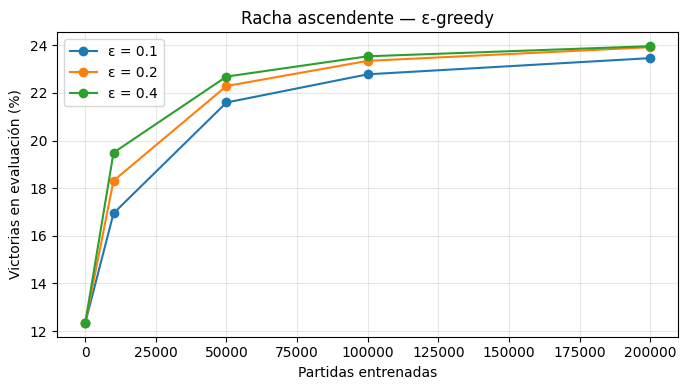

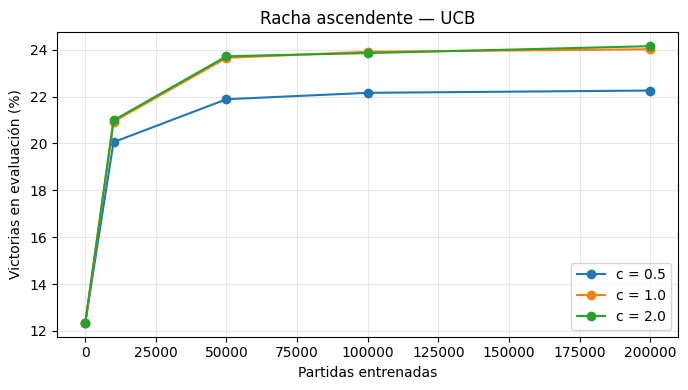

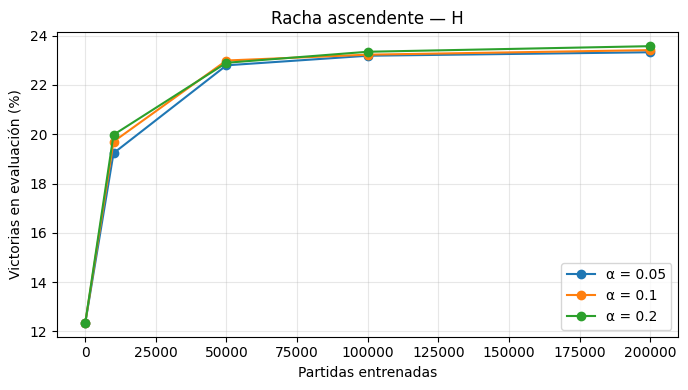

In [ ]:
for metodo, (nombre, parametros) in CONFIGURACIONES.items():
    plt.figure(figsize=(7, 4))
    for parametro in parametros:
        media = resultados[metodo][parametro].mean(axis=0)
        plt.plot(PUNTOS, media, marker="o", label=f"{nombre} = {parametro}")
    plt.title(f"Racha ascendente — {metodo}")
    plt.xlabel("Partidas entrenadas")
    plt.ylabel("Victorias en evaluación (%)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


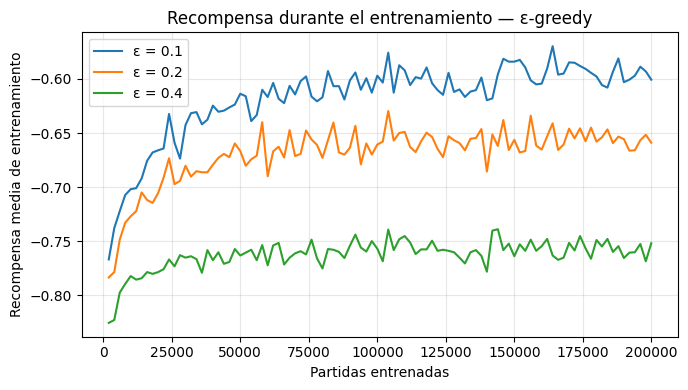

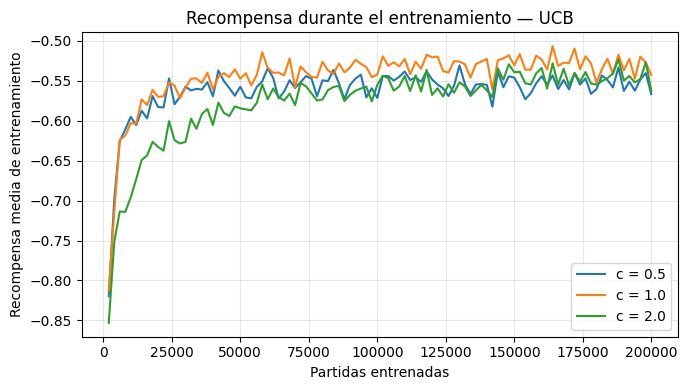

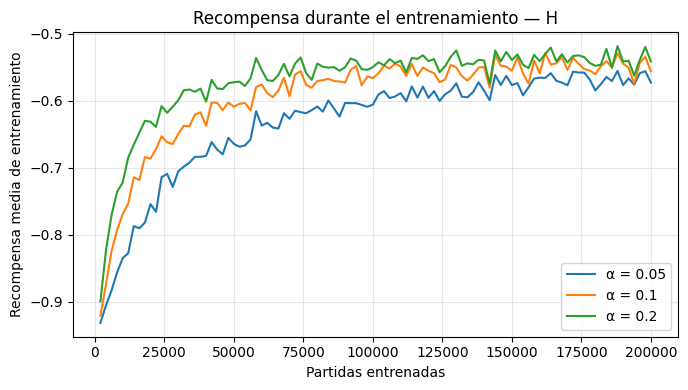

In [ ]:
puntos_recompensas = range(BLOQUE_RECOMPENSAS, PUNTOS[-1] + 1, BLOQUE_RECOMPENSAS)
for metodo, (nombre, parametros) in CONFIGURACIONES.items():
    plt.figure(figsize=(7, 4))
    for parametro in parametros:
        media = recompensas[metodo][parametro].mean(axis=0)
        plt.plot(puntos_recompensas, media, label=f"{nombre} = {parametro}")
    plt.title(f"Recompensa durante el entrenamiento — {metodo}")
    plt.xlabel("Partidas entrenadas")
    plt.ylabel("Recompensa media de entrenamiento")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


## 9. Mejor configuración probada por método



<table style="border-collapse: collapse; text-align: left;">
<thead><tr style="background-color: #f0f0f0; color: #111111;">
<th style="padding: 10px 16px;">Método</th><th style="padding: 10px 16px;">Mejor configuración probada</th><th style="padding: 10px 16px;">Victorias</th>
</tr></thead>
<tbody>
<tr style="background-color: #2ca02c; color: #000000;"><td style="padding: 10px 16px;">UCB</td><td style="padding: 10px 16px;">c = 2</td><td style="padding: 10px 16px;">24,15 %</td></tr>
<tr style="background-color: #2ca02c; color: #000000;"><td style="padding: 10px 16px;">ε-greedy</td><td style="padding: 10px 16px;">ε = 0,4</td><td style="padding: 10px 16px;">23,96 %</td></tr>
<tr style="background-color: #2ca02c; color: #000000;"><td style="padding: 10px 16px;">Preferencias H</td><td style="padding: 10px 16px;">α = 0,2</td><td style="padding: 10px 16px;">23,57 %</td></tr>
</tbody>
</table>
